# Ghana staple food prices, 2006 to 2023

Question: Which staple foods rose fastest in price, and in which markets?

Data: WFP Food Prices for Ghana (Humanitarian Data Exchange).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data and add a year column
df = pd.read_csv('wfp_food_prices_gha.csv', parse_dates=['date'])
df['year'] = df.date.dt.year
print(df.shape)
df.head()

(37263, 17)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,year
0,2006-01-15,ASHANTI,KMA,Kumasi,215,6.68,-1.62,cereals and tubers,Cassava,68,91 KG,actual,Wholesale,GHS,10.31,11.21,2006
1,2006-01-15,ASHANTI,KMA,Kumasi,215,6.68,-1.62,cereals and tubers,Maize,51,100 KG,actual,Wholesale,GHS,25.40,27.61,2006
2,2006-01-15,ASHANTI,KMA,Kumasi,215,6.68,-1.62,cereals and tubers,Rice (local),71,50 KG,actual,Wholesale,GHS,33.06,35.93,2006
3,2006-01-15,ASHANTI,KMA,Kumasi,215,6.68,-1.62,cereals and tubers,Sorghum,65,109 KG,actual,Wholesale,GHS,38.25,41.58,2006
4,2006-01-15,ASHANTI,KMA,Kumasi,215,6.68,-1.62,cereals and tubers,Yam,99,250 KG,actual,Wholesale,GHS,63.38,68.89,2006


## Clean

Retail prices use price per KG. Wholesale prices use sacks of different sizes (50 KG, 100 KG and so on). Mixing the two gives wrong trends, so this analysis uses wholesale prices only and converts every sack price to a price per KG.

In [2]:
# Keep wholesale rows with a weight in the unit
w = df[df.pricetype == 'Wholesale'].copy()
w['kg'] = w.unit.str.extract(r'^(\d+)\s*KG$')[0].astype(float)
w = w.dropna(subset=['kg'])

# Price per KG in cedis and in US dollars
w['ghs_kg'] = w.price / w.kg
w['usd_kg'] = w.usdprice / w.kg

In [3]:
# Keep six staples with data from 2006 to 2023
keep = {('Maize','100 KG'), ('Rice (imported)','50 KG'), ('Rice (local)','50 KG'),
        ('Cassava','91 KG'), ('Sorghum','109 KG'), ('Millet','93 KG')}
w = w[[(c, u) in keep for c, u in zip(w.commodity, w.unit)]]
w.groupby('commodity').size()

commodity
Cassava            2217
Maize              2555
Millet             1500
Rice (imported)    1759
Rice (local)       2097
Sorghum            1389
dtype: int64

## Yearly price per KG

The median across markets reduces the effect of outliers. 2023 holds data to July only, so the trend stops at 2022.

In [4]:
yr = w.groupby(['year', 'commodity']).agg(ghs=('ghs_kg', 'median'), usd=('usd_kg', 'median')).reset_index()
ghs = yr.pivot(index='year', columns='commodity', values='ghs')
usd = yr.pivot(index='year', columns='commodity', values='usd')
ghs.round(2)

commodity,Cassava,Maize,Millet,Rice (imported),Rice (local),Sorghum
year,,,,,,
2006,0.14,0.18,0.32,0.70,0.57,0.25
2007,0.14,0.21,0.32,0.73,0.61,0.26
2008,0.18,0.44,0.64,1.11,0.86,0.48
2009,0.22,0.55,0.72,1.32,1.07,0.55
2010,0.25,0.45,0.66,1.38,1.05,0.54
2011,0.26,0.65,0.77,1.54,1.25,0.64
2012,0.41,0.88,1.13,3.05,1.46,0.81
2013,0.55,0.74,1.21,3.40,1.66,0.92
2014,0.44,1.03,1.15,3.80,2.00,0.92


## Cedi prices against dollar prices

Both charts set 2007 to 100.

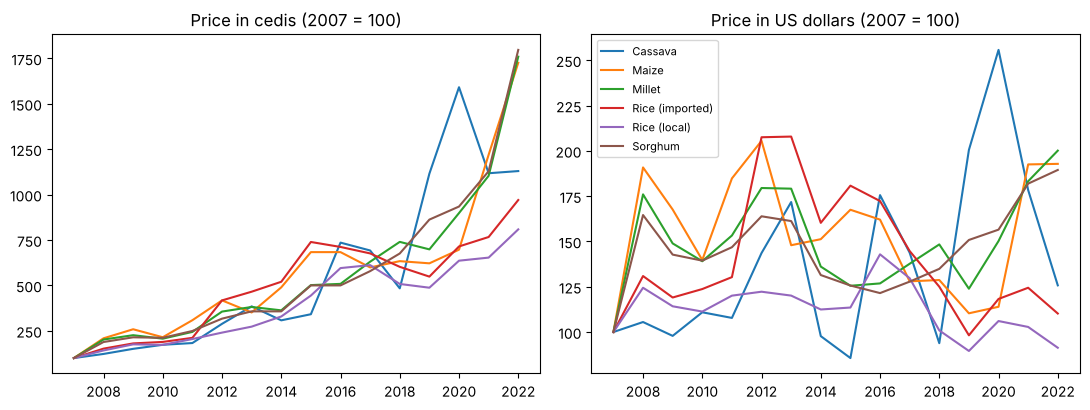

In [5]:
g = ghs.loc[2007:2022] / ghs.loc[2007] * 100
u = usd.loc[2007:2022] / usd.loc[2007] * 100

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for c in g.columns:
    ax[0].plot(g.index, g[c], label=c)
    ax[1].plot(u.index, u[c], label=c)
ax[0].set_title('Price in cedis (2007 = 100)')
ax[1].set_title('Price in US dollars (2007 = 100)')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
# Total change, 2007 to 2022 and 2019 to 2022
summary = pd.DataFrame({
    'cedi_2007_2022_pct': (ghs.loc[2022] / ghs.loc[2007] - 1) * 100,
    'usd_2007_2022_pct': (usd.loc[2022] / usd.loc[2007] - 1) * 100,
    'cedi_2019_2022_pct': (ghs.loc[2022] / ghs.loc[2019] - 1) * 100,
    'usd_2019_2022_pct': (usd.loc[2022] / usd.loc[2019] - 1) * 100,
}).round(0)
summary.sort_values('cedi_2007_2022_pct', ascending=False)

,cedi_2007_2022_pct,usd_2007_2022_pct,cedi_2019_2022_pct,usd_2019_2022_pct
commodity,,,,
Sorghum,1697.0,89.0,108.0,26.0
Millet,1659.0,100.0,152.0,61.0
Maize,1626.0,93.0,178.0,75.0
Cassava,1030.0,26.0,1.0,-37.0
Rice (imported),870.0,10.0,77.0,12.0
Rice (local),709.0,-9.0,66.0,2.0


## Maize by market, 2019 to 2022

Only markets with maize data in both years.

In [7]:
m = w[(w.commodity == 'Maize') & w.year.isin([2019, 2022])]
p = m.groupby(['market', 'year']).ghs_kg.median().unstack().dropna()
p['pct'] = (p[2022] / p[2019] - 1) * 100
p = p.sort_values('pct', ascending=False)
p.round(2)

year,2019,2022,pct
market,,,
Garu,0.94,3.39,261.25
Koforidua,1.10,3.59,226.09
Tamale,0.96,3.00,212.11
Bolga,1.16,3.39,192.50
Kumasi,1.61,4.60,186.60
Yendi,0.86,2.46,186.33
Kintampo,0.93,2.66,185.55
Sunyani,1.15,3.18,175.32
Cape Coast,1.90,5.18,172.83


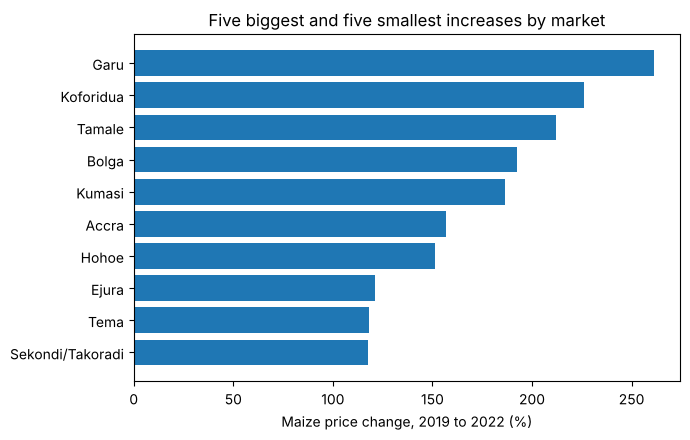

In [8]:
top = pd.concat([p.head(5), p.tail(5)])
plt.figure(figsize=(7, 4.5))
plt.barh(top.index[::-1], top.pct[::-1])
plt.xlabel('Maize price change, 2019 to 2022 (%)')
plt.title('Five biggest and five smallest increases by market')
plt.tight_layout()
plt.show()

## Findings

1. In cedis, maize, millet and sorghum rose about 1,600% to 1,700% from 2007 to 2022. In US dollars the rise was 89% to 100%. Most of the cedi increase comes from the falling value of the cedi.
2. From 2019 to 2022, maize rose 178% in cedis and 75% in dollars. Local rice rose 66% in cedis and 2% in dollars. Cassava stayed flat in cedis (1%).
3. Maize prices rose most in Garu (261%), Koforidua (226%), Tamale (212%), Bolga (193%) and Kumasi (187%). They rose least in Sekondi/Takoradi (117%), Tema (118%) and Ejura (121%).

Limits: the number of markets reporting grew in 2019, so the early and late medians do not cover the same markets. Treat small differences with care.